# Group comparison: six canonical resignation models

Evaluate FT-Transformer, CatBoost, XGBoost, LightGBM, EBM and TabNet using the same **80,000 development OOF records and five frozen folds**. No model training, weight loading or formal-holdout evaluation occurs here.

**Primary ranking:** pooled Average Precision (AP), descending; exact ties use alphabetical model name. Mean fold AP is a separate descriptive comparison. AP means scikit-learn Average Precision, not trapezoidal PR area. A numerical leader is not automatically a useful predictor.

Run All displays the complete comparison. **EXPORT_RESULTS=False** preserves existing files. Enable it deliberately to regenerate compatible aggregate tables, summary and eight figures. No employee-level outputs are exported.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_curve, roc_curve

ROOT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "configs/analysis_registry.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.inputs import load_group_inputs
from src.evaluation.oof_validation import validate_oof_predictions
from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.calibration import expected_calibration_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
out = ROOT / "results/comparison"
print(f"Project root: {ROOT}")
EXPORT_RESULTS=False
model_colors = {"FT-Transformer": "#7651a8", "CatBoost": "#d67924", "XGBoost": "#2665ad",
                "LightGBM": "#188574", "EBM": "#a94868", "TabNet": "#707e28"}
GREY = "#677580"
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
rendered_figures = {}
def finish_figure(fig, filename, caption):
    rendered_figures[filename] = fig
    plt.show()
    plt.close(fig)
    display(Markdown("**Interpretation:** " + caption))
print("Mode:", "explicit aggregate export" if EXPORT_RESULTS else "read-only comparison")


Project root: <project root>
Mode: read-only comparison


## 1. Canonical inputs and alignment

The shared loader verifies source/split checksums and each model's IDs, folds, original targets, names and probabilities. FT and EBM use formal manifests. Invalid or missing evidence stops execution; historical files are not a fallback.

The canonical FT-Transformer input is `results/models/ft_transformer/strict_nested/oof_predictions.csv`. Its formal strict-nested evaluation is complete: five outer folds each evaluate eight candidates on an inner split (40 inner evaluations total), select a fold-specific winner and epoch count, refit that winner on the full outer-training partition, and predict only the untouched outer fold. Fitting protocols still differ across models, so small score gaps require cautious interpretation.

Inspect aggregate inventory and confirm common ordering. Holdout IDs are used only to verify exclusion; holdout predictors/labels are not parsed.


In [2]:
registry, frames = load_group_inputs(ROOT)
expected_models = {"FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"}
if set(frames) != expected_models:
    raise ValueError("The group comparison requires exactly the six declared headline models.")

split_registry = pd.read_csv(ROOT / "data/processed/split_registry.csv")
reference = frames["FT-Transformer"]
source_targets = reference[["Employee_ID", "y_true"]].rename(columns={"y_true": "Resigned"})
holdout_ids = set(split_registry.loc[split_registry.partition == "holdout", "Employee_ID"])
if len(reference) != 80000 or reference.Employee_ID.nunique() != 80000:
    raise ValueError("Expected 80,000 unique development OOF IDs.")
reference_ids = reference.Employee_ID.to_numpy()
reference_y = reference.y_true.astype(int).to_numpy()
input_rows = []
for model, predictions in frames.items():
    entry = registry["models"][model]
    validate_oof_predictions(predictions, split_registry, source_data=source_targets,
                             expected_model_name=entry.get("model_name", model))
    if not np.array_equal(predictions.cv_fold.to_numpy(), reference.cv_fold.to_numpy()):
        raise ValueError(f"{model}: folds are not aligned.")
    if not np.array_equal(predictions.Employee_ID.to_numpy(), reference_ids):
        raise ValueError(f"{model}: IDs are not aligned after validation.")
    if not np.array_equal(predictions.y_true.astype(int).to_numpy(), reference_y):
        raise ValueError(f"{model}: targets are not aligned after validation.")
    entry = registry["models"][model]
    input_rows.append({
        "model": model,
        "oof_rows": len(predictions),
        "outer_folds": predictions.cv_fold.nunique(),
        "multi_candidate_tuning_complete": entry["tuning_complete"],
        "protocol": entry["protocol"],
        "canonical_input": entry["oof_path"],
    })
input_inventory = pd.DataFrame(input_rows)
display(input_inventory)

assert set(reference_ids).isdisjoint(holdout_ids)
print("No comparison rows dropped; formal holdout overlap: 0.")


Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,model,oof_rows,outer_folds,multi_candidate_tuning_complete,protocol,canonical_input
0,FT-Transformer,80000,5,True,strict nested FT01-FT08 inner AP candidate selection and full outer-training winner refit,results/models/ft_transformer/strict_nested/oof_predictions.csv
1,CatBoost,80000,5,True,"IT25100565 strict nested selection of 26 candidates per outer fold by inner log-loss, ...",results/models/catboost/oof_predictions.csv
2,XGBoost,80000,5,True,Member 3 primary P1 one-hot; strict nested 8-candidate selection; P2/P3 preprocessing ...,results/models/xgboost/oof_predictions.csv
3,LightGBM,80000,5,True,strict nested candidate selection,results/models/lightgbm/strict_nested/oof_predictions.csv
4,EBM,80000,5,True,nested inner-AP selection among three raw candidates; standardized variants are sensit...,results/models/ebm/individual_IT25100429/oof_predictions.csv
5,TabNet,80000,5,True,strict nested candidate selection,results/models/tabnet/oof_predictions.csv


No comparison rows dropped; formal holdout overlap: 0.


## 2. Class imbalance and Dummy baselines

The roughly 90/10 imbalance makes accuracy a weak standalone measure: predicting everyone negative detects no resignations despite high accuracy. Retain the original target distribution; no resampling occurs here.

Validate both saved Dummy inputs on the same IDs, labels and folds. Dummy Prior estimates prevalence from outer training, so its pooled AP can differ slightly from overall prevalence. Dummy Most Frequent is the constant-negative reference. Baselines remain outside the six-model ranking.


In [3]:
target_counts = pd.Series(reference_y).value_counts().reindex([0, 1], fill_value=0)
prevalence = float(reference_y.mean())
constant_brier = prevalence * (1 - prevalence)
majority_accuracy = float(target_counts.max() / target_counts.sum())
display(target_counts.rename_axis("Resigned").to_frame("development_rows"))
print(f"Positive prevalence: {prevalence:.2%}; majority-only accuracy: {majority_accuracy:.2%}.")
print(f"Negative/positive ratio: {target_counts[0] / target_counts[1]:.2f}:1; no resampling.")
baseline_rows = []
for name, filename in [
    ("Dummy Prior", "dummy_prior_oof_predictions.csv"),
    ("Dummy Most Frequent", "dummy_most_frequent_oof_predictions.csv"),
]:
    predictions = pd.read_csv(ROOT / "results/baselines" / filename)
    validate_oof_predictions(predictions, split_registry, source_data=source_targets, expected_model_name=name)
    metrics = calculate_binary_metrics(predictions.y_true, predictions.y_probability)
    baseline_rows.append({
        "model": name,
        **{key: metrics[key] for key in ["average_precision", "roc_auc", "brier_score", "accuracy", "recall", "f1"]},
    })
baselines = pd.DataFrame(baseline_rows)
display(baselines)
print(f"Constant prevalence-probability reference: AP={prevalence:.6f}; Brier={prevalence * (1 - prevalence):.6f}.")


,development_rows
Resigned,
0,71992
1,8008


Positive prevalence: 10.01%; majority-only accuracy: 89.99%.
Negative/positive ratio: 8.99:1; no resampling.


,model,average_precision,roc_auc,brier_score,accuracy,recall,f1
0,Dummy Prior,0.100085,0.499917,0.090080,0.899900,0.000000,0.000000
1,Dummy Most Frequent,0.100100,0.500000,0.100100,0.899900,0.000000,0.000000


Constant prevalence-probability reference: AP=0.100100; Brier=0.090080.


## 3. Metrics and exploratory thresholds

Pooled AP is primary; ROC-AUC measures discrimination, Brier measures probability error and ECE uses ten equal-width bins. Good base-rate probability error does not imply useful ranking. Sample fold SD is **descriptive variation**, not a confidence interval or significance test: training partitions overlap.

Maximum-F1 fields are retained for compatibility. Their thresholds are searched and scored on the same OOF labels: **exploratory and optimistic**, not independently validated operating points. No threshold is adopted or frozen.


In [4]:
rows, fold_rows, classification_rows = [], [], []
confusion_counts = {}
for model, predictions in frames.items():
    y = predictions.y_true.astype(int).to_numpy()
    probability = predictions.y_probability.astype(float).to_numpy()
    metrics = calculate_binary_metrics(y, probability, threshold=0.50)
    confusion_counts[model] = np.array([[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]])

    # Searching thresholds on these same OOF labels gives a descriptive maximum,
    # not an independently validated operating threshold.
    precision, recall, thresholds = precision_recall_curve(y, probability)
    denominator = precision[:-1] + recall[:-1]
    threshold_f1 = np.divide(
        2 * precision[:-1] * recall[:-1], denominator,
        out=np.zeros_like(thresholds), where=denominator > 0,
    )
    best_index = int(np.argmax(threshold_f1))
    best_threshold = float(thresholds[best_index])
    best_metrics = calculate_binary_metrics(y, probability, threshold=best_threshold)
    rows.append({
        "model": model,
        "protocol": registry["models"][model]["protocol"],
        "tuning_complete": registry["models"][model]["tuning_complete"],
        "pooled_average_precision": metrics["average_precision"],
        "pooled_roc_auc": metrics["roc_auc"],
        "brier_score": metrics["brier_score"],
        "ece_10_bins": expected_calibration_error(y, probability, 10),
        "f1_at_0_5": metrics["f1"],
        "f1_max_oof": best_metrics["f1"],
        "f1_max_threshold": best_threshold,
    })
    classification_rows.append({
        "model": model,
        **{key: metrics[key] for key in ["precision", "recall", "f1", "balanced_accuracy", "accuracy", "predicted_positive_rate"]},
    })
    for fold, subset in predictions.groupby("cv_fold", sort=True):
        fold_metrics = calculate_binary_metrics(subset.y_true, subset.y_probability)
        fold_rows.append({
            "model": model, "cv_fold": int(fold),
            **{key: fold_metrics[key] for key in ["average_precision", "roc_auc", "brier_score"]},
        })

folds = pd.DataFrame(fold_rows)
stability = folds.groupby("model").agg(
    cv_ap_mean=("average_precision", "mean"),
    cv_ap_sd=("average_precision", "std"),
    cv_roc_mean=("roc_auc", "mean"),
    cv_roc_sd=("roc_auc", "std"),
).reset_index()
comparison = pd.DataFrame(rows).merge(stability, on="model", validate="one_to_one")
comparison = comparison.sort_values(["pooled_average_precision", "model"], ascending=[False, True]).reset_index(drop=True)
comparison["ap_uplift_over_prevalence"] = comparison.pooled_average_precision - prevalence

display(comparison[[
    "model", "pooled_average_precision", "ap_uplift_over_prevalence", "cv_ap_mean", "cv_ap_sd",
    "pooled_roc_auc", "brier_score", "ece_10_bins",
]])
display(folds.pivot(index="model", columns="cv_fold", values="average_precision").loc[comparison.model])
model_order = comparison.model.tolist()
indexed = comparison.set_index("model")
classification = pd.DataFrame(classification_rows).set_index("model").loc[model_order].reset_index()
classification_display = classification.copy()
classification_display.loc[classification_display.predicted_positive_rate == 0, "precision"] = np.nan
positions = np.arange(len(model_order))
colors = [model_colors[m] for m in model_order]


,model,pooled_average_precision,ap_uplift_over_prevalence,cv_ap_mean,cv_ap_sd,pooled_roc_auc,brier_score,ece_10_bins
0,XGBoost,0.101181,0.001081,0.101643,0.000990,0.502471,0.175329,0.227166
1,LightGBM,0.100153,0.000053,0.100202,0.002446,0.498740,0.180215,0.234650
2,TabNet,0.099965,-0.000135,0.101700,0.003876,0.499317,0.186177,0.240548
3,CatBoost,0.099860,-0.000240,0.100180,0.002081,0.499605,0.090102,0.003668
4,EBM,0.099000,-0.001100,0.099558,0.002073,0.495976,0.090109,0.003337
5,FT-Transformer,0.098648,-0.001452,0.098065,0.002638,0.497980,0.153086,0.162174


cv_fold,1,2,3,4,5
model,,,,,
XGBoost,0.100518,0.101290,0.101176,0.103077,0.102152
LightGBM,0.102428,0.100170,0.101850,0.100389,0.096173
TabNet,0.097812,0.102024,0.100511,0.108087,0.100067
CatBoost,0.097485,0.099285,0.101263,0.099861,0.103005
EBM,0.096220,0.101301,0.101141,0.099062,0.100064
FT-Transformer,0.096581,0.101352,0.095313,0.100386,0.096695


## 4. Primary pooled-AP ranking

The first panel uses a zero-based AP axis with prevalence and measured Dummy references. The second expands **absolute AP uplift in percentage points**; zero means equal to prevalence, not zero predictive accuracy.

Small numerical uplift does not establish statistical significance, practical utility or a validated retention policy.


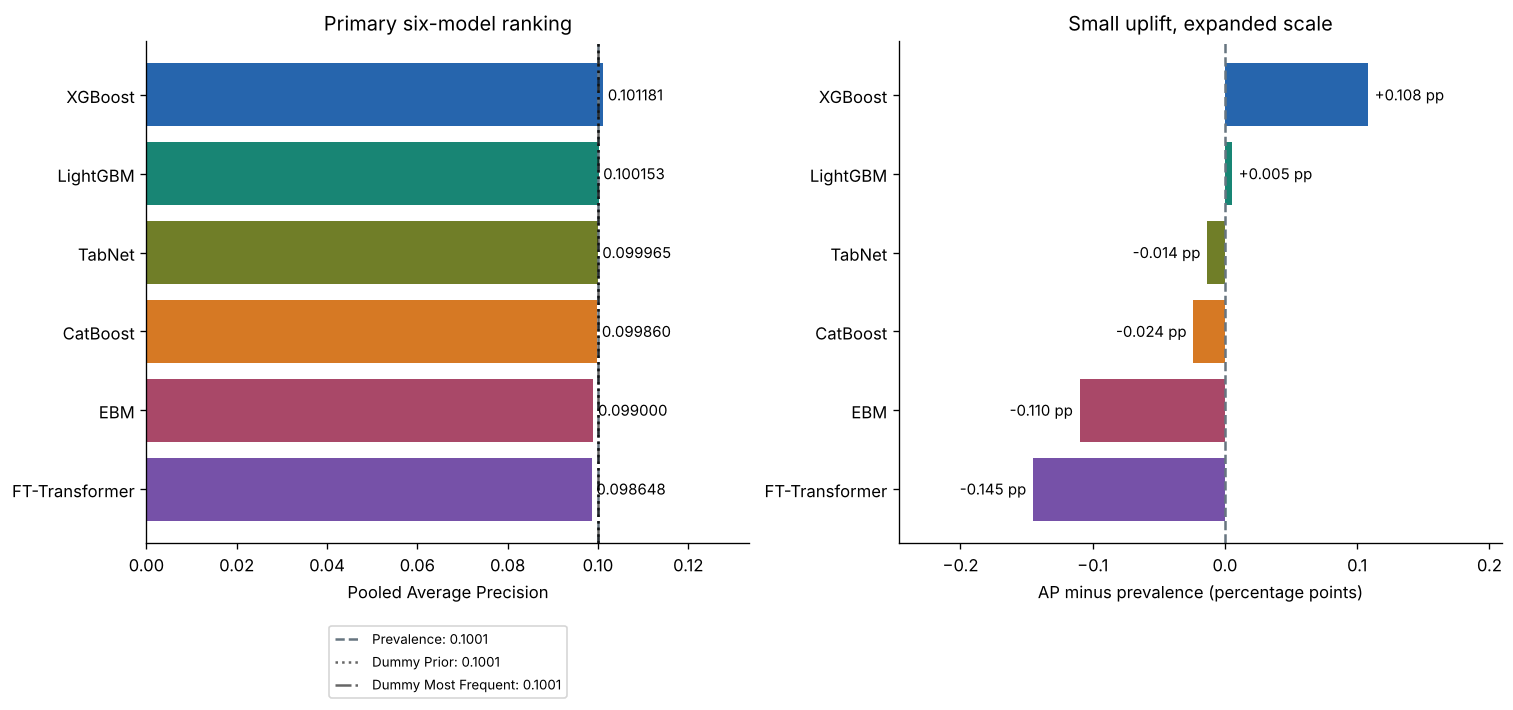

**Interpretation:** Expanded uplift reveals small differences; zero-based AP shows that every result remains near no-skill.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.8), layout="constrained")
axes[0].barh(positions, comparison.pooled_average_precision, color=colors)
axes[0].axvline(prevalence, color=GREY, ls="--", label=f"Prevalence: {prevalence:.4f}")
for baseline, linestyle in zip(baselines.itertuples(), [":", "-."]):
    axes[0].axvline(baseline.average_precision, color="black", ls=linestyle, alpha=0.6,
                    label=f"{baseline.model}: {baseline.average_precision:.4f}")
for i, value in enumerate(comparison.pooled_average_precision):
    axes[0].text(value + 0.001, i, f"{value:.6f}", va="center", fontsize=9)
axes[0].set(xlim=(0, max(comparison.pooled_average_precision.max(), prevalence) * 1.32),
            yticks=positions, yticklabels=model_order, xlabel="Pooled Average Precision", title="Primary six-model ranking")
axes[0].invert_yaxis()
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
uplift_pp = comparison.ap_uplift_over_prevalence * 100
bars = axes[1].barh(positions, uplift_pp, color=colors)
axes[1].bar_label(bars, labels=[f"{value:+.3f} pp" for value in uplift_pp], padding=4, fontsize=9)
axes[1].axvline(0, color=GREY, ls="--")
axes[1].set(yticks=positions, yticklabels=model_order, xlabel="AP minus prevalence (percentage points)", title="Small uplift, expanded scale")
axes[1].invert_yaxis()
axes[1].margins(x=0.4)
finish_figure(fig, "figure_01_average_precision_comparison.png", "Expanded uplift reveals small differences; zero-based AP shows that every result remains near no-skill.")


## 5. Five-fold stability

Show all five outer-fold AP scores with mean and one sample SD. Fixed offsets separate points without random jitter. The x-axis is deliberately zoomed and labelled.

Error bars describe variability across overlapping-training evaluations; they are not confidence intervals, significance tests or a replacement for pooled-AP ranking.


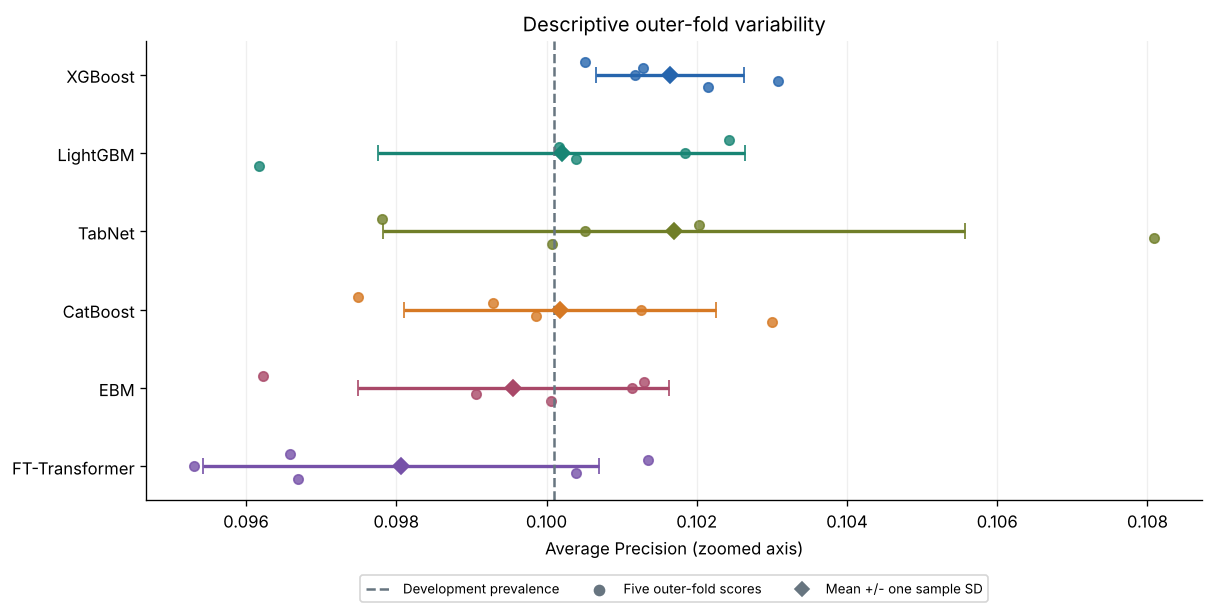

**Interpretation:** Fold variability is comparable to or larger than many between-model gaps; SD does not quantify significance.

In [6]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
offsets = np.linspace(-0.16, 0.16, 5)
for i, model in enumerate(model_order):
    values = folds.loc[folds.model == model].sort_values("cv_fold").average_precision.to_numpy()
    ax.scatter(values, i + offsets, color=model_colors[model], s=32, alpha=0.8)
    ax.errorbar(values.mean(), i, xerr=values.std(ddof=1), fmt="D", color=model_colors[model], capsize=5, markersize=7, lw=2)
ax.axvline(prevalence, color=GREY, ls="--", label="Development prevalence")
ax.scatter([], [], color=GREY, label="Five outer-fold scores")
ax.plot([], [], "D", color=GREY, label="Mean +/- one sample SD")
ax.set(yticks=positions, yticklabels=model_order, xlabel="Average Precision (zoomed axis)", title="Descriptive outer-fold variability")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
finish_figure(fig, "figure_03_fold_ap_stability.png", "Fold variability is comparable to or larger than many between-model gaps; SD does not quantify significance.")


## 6. Pooled versus mean-fold ranks

Pooled AP combines scores from independently selected fold models; mean fold AP averages within-fold scores. AP is nonlinear and score scales can differ, so rankings may disagree.

Connected lines show ordinal ranks, not effect sizes or significance. Exact ties use alphabetical model name.


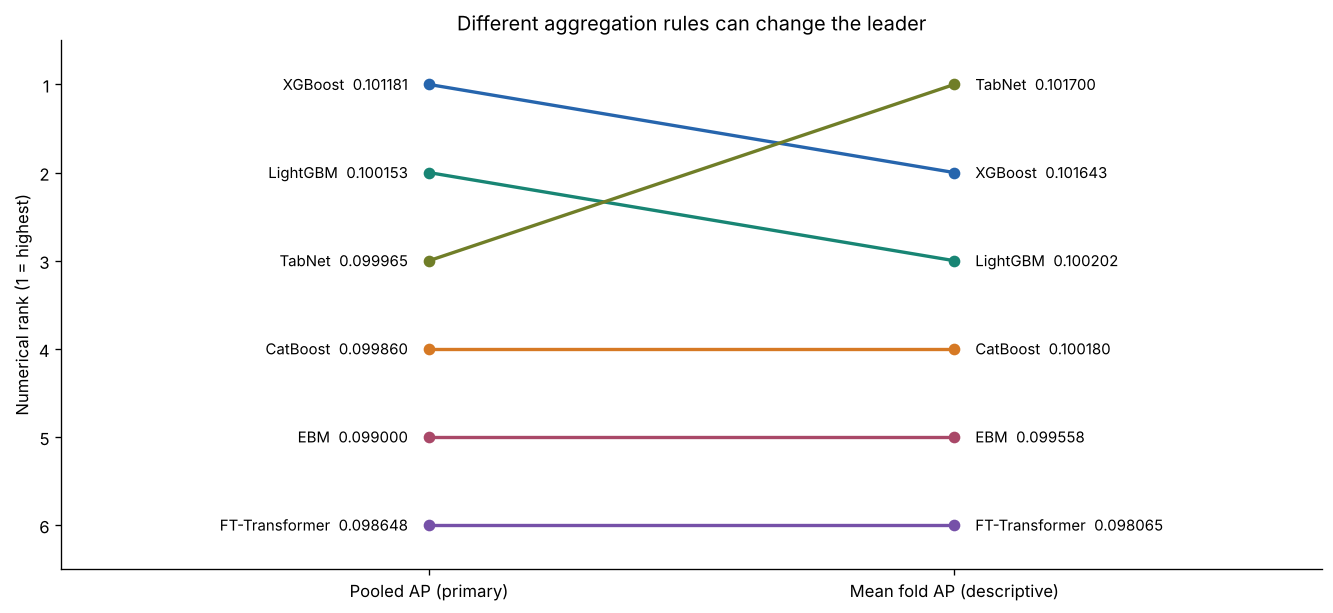

**Interpretation:** Report both aggregations transparently; a rank change or tiny score advantage does not establish practical superiority.

In [7]:
mean_order = comparison.sort_values(["cv_ap_mean", "model"], ascending=[False, True]).model.tolist()
pooled_rank = {model: i + 1 for i, model in enumerate(model_order)}
mean_rank = {model: i + 1 for i, model in enumerate(mean_order)}
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
for model in model_order:
    left, right = pooled_rank[model], mean_rank[model]
    ax.plot([0, 1], [left, right], "o-", color=model_colors[model], lw=2)
    ax.text(-0.04, left, f"{model}  {indexed.loc[model, 'pooled_average_precision']:.6f}", ha="right", va="center", fontsize=9)
    ax.text(1.04, right, f"{model}  {indexed.loc[model, 'cv_ap_mean']:.6f}", ha="left", va="center", fontsize=9)
ax.set(xlim=(-0.7, 1.7), ylim=(6.5, 0.5), xticks=[0, 1], xticklabels=["Pooled AP (primary)", "Mean fold AP (descriptive)"],
       yticks=range(1, 7), ylabel="Numerical rank (1 = highest)", title="Different aggregation rules can change the leader")
finish_figure(fig, "figure_04_pooled_vs_mean_fold_ranks.png", "Report both aggregations transparently; a rank change or tiny score advantage does not establish practical superiority.")


## 7. Minority-class ranking: precision-recall curves

Use common 0-1 axes and a prevalence reference. Legend values use Average Precision, not trapezoidal PR area. Curves near chance can overlap; the AP/uplift table provides exact values.

High-precision endpoints at almost zero recall are not evidence of useful general detection. Do not select an operating threshold from this figure.


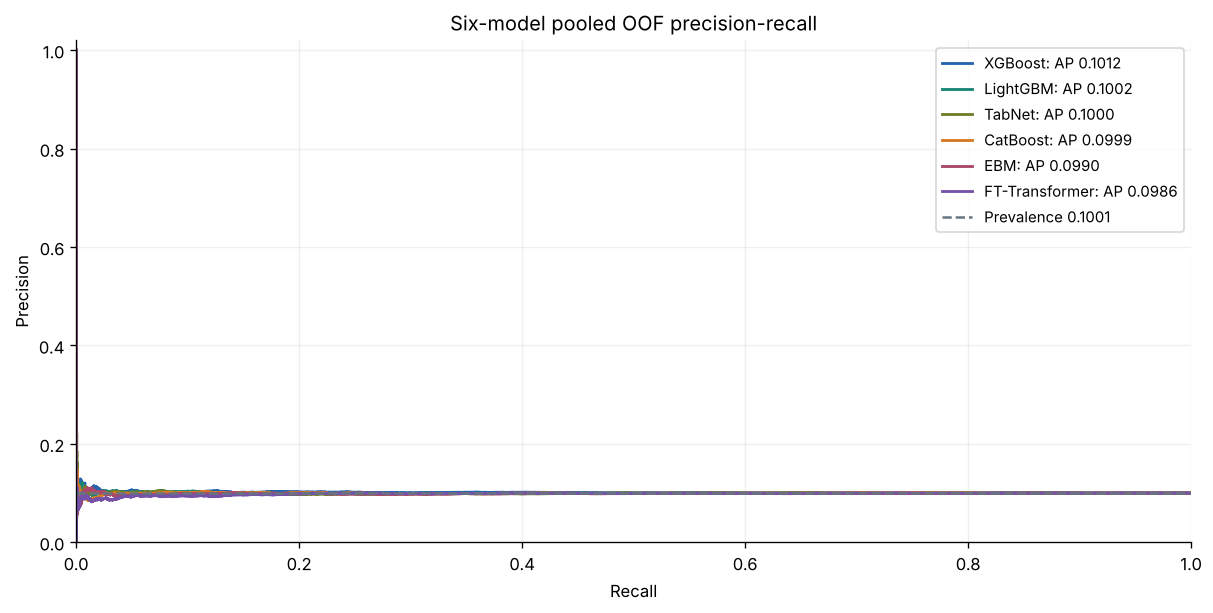

**Interpretation:** Most of the recall range remains near prevalence; endpoint spikes alone do not establish useful minority-class ranking.

In [8]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for model in model_order:
    predictions = frames[model]
    precision, recall, _ = precision_recall_curve(predictions.y_true, predictions.y_probability)
    ax.plot(recall, precision, color=model_colors[model], lw=1.7,
            label=f"{model}: AP {indexed.loc[model, 'pooled_average_precision']:.4f}")
ax.axhline(prevalence, color=GREY, ls="--", label=f"Prevalence {prevalence:.4f}")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Precision", title="Six-model pooled OOF precision-recall")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.2)
finish_figure(fig, "figure_05_precision_recall_comparison.png", "Most of the recall range remains near prevalence; endpoint spikes alone do not establish useful minority-class ranking.")


## 8. Overall ranking: ROC curves

ROC-AUC measures discrimination across both classes; 0.5 is the chance reference. Use common 0-1 scales and the diagonal. ROC and PR answer different questions under imbalance.

These are development OOF diagnostics, not formal-holdout results.


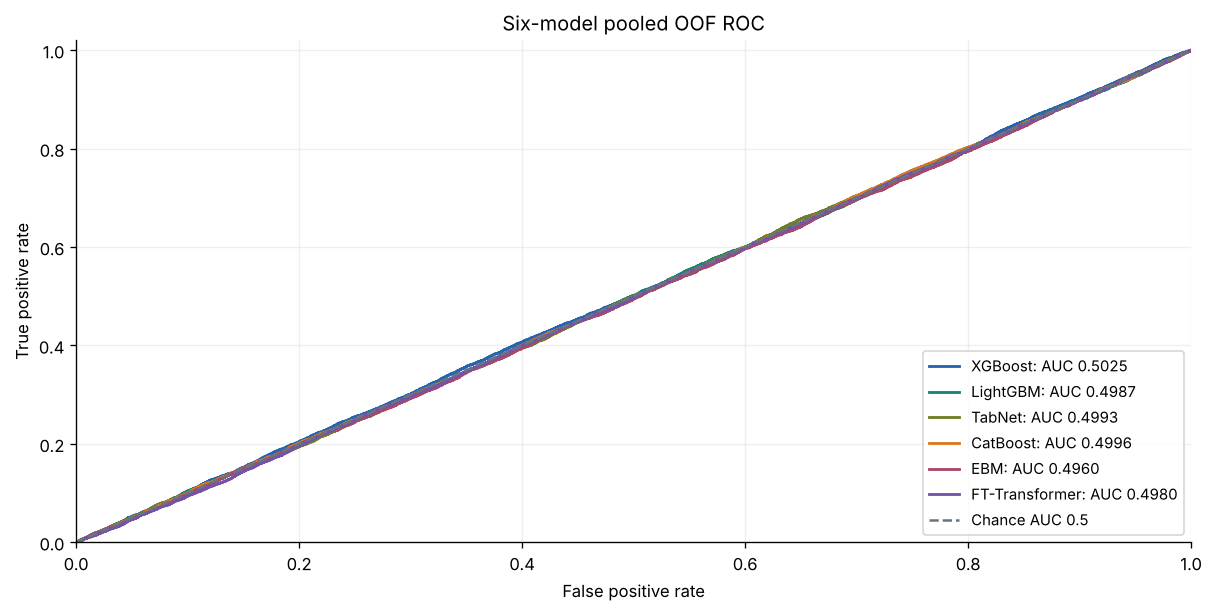

**Interpretation:** Curves close to the diagonal support weak discrimination regardless of the numerical AP leader.

In [9]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for model in model_order:
    predictions = frames[model]
    false_positive_rate, true_positive_rate, _ = roc_curve(predictions.y_true, predictions.y_probability)
    ax.plot(false_positive_rate, true_positive_rate, color=model_colors[model], lw=1.7,
            label=f"{model}: AUC {indexed.loc[model, 'pooled_roc_auc']:.4f}")
ax.plot([0, 1], [0, 1], ls="--", color=GREY, label="Chance AUC 0.5")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False positive rate", ylabel="True positive rate", title="Six-model pooled OOF ROC")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
finish_figure(fig, "figure_02_roc_auc_comparison.png", "Curves close to the diagonal support weak discrimination regardless of the numerical AP leader.")


## 9. Probability quality

Brier and ten-bin ECE have separate scales and meanings; lower is better for each. Compare Brier to the constant-prevalence score p(1-p). ECE depends on the selected bins.

Nearly constant base-rate scores can have good probability error without useful discrimination. Weighting can shift score scales. Detailed reliability and calibration belong to the calibration notebook; no calibrator is fitted here.


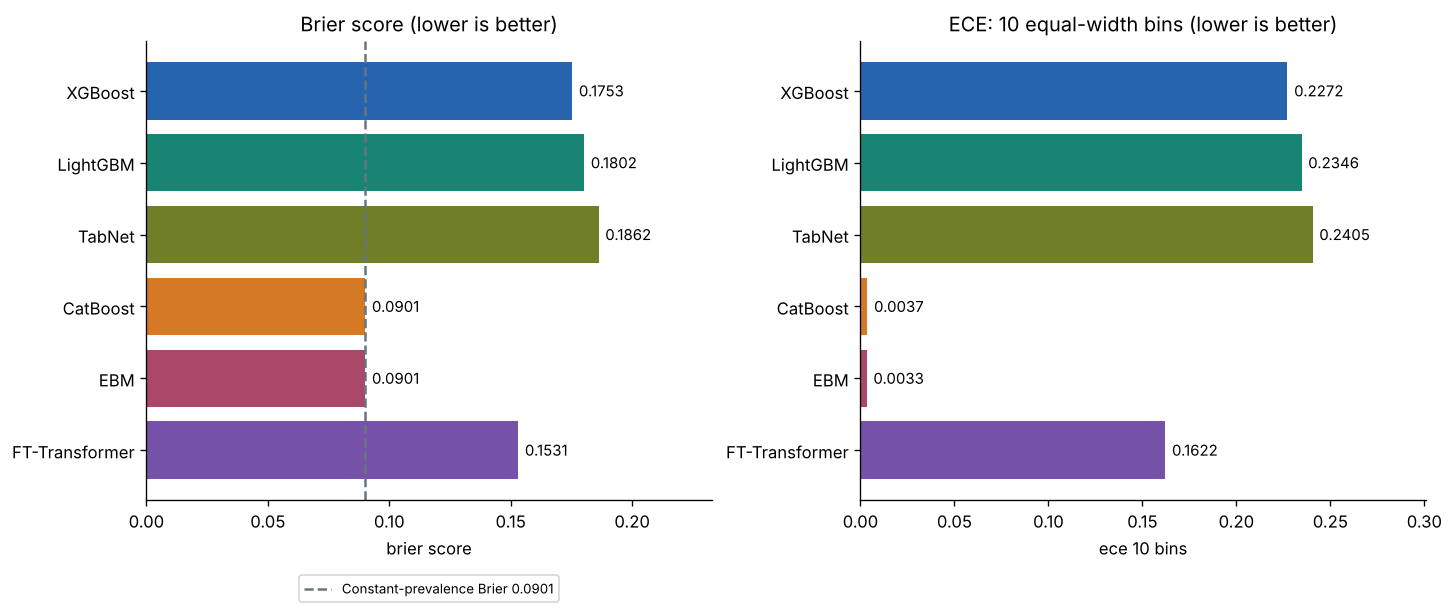

**Interpretation:** Good probability error can coexist with chance-level ranking; Brier and ECE complement AP rather than define a combined quality score.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, metric, title in [(axes[0], "brier_score", "Brier score (lower is better)"),
                         (axes[1], "ece_10_bins", "ECE: 10 equal-width bins (lower is better)")]:
    bars = ax.barh(positions, indexed.loc[model_order, metric], color=colors)
    ax.bar_label(bars, fmt="%.4f", padding=4, fontsize=9)
    ax.set(yticks=positions, yticklabels=model_order, xlabel=metric.replace("_", " "), title=title)
    ax.invert_yaxis()
    ax.margins(x=0.25)
axes[0].axvline(constant_brier, color=GREY, ls="--", label=f"Constant-prevalence Brier {constant_brier:.4f}")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
finish_figure(fig, "figure_06_probability_quality_comparison.png", "Good probability error can coexist with chance-level ranking; Brier and ECE complement AP rather than define a combined quality score.")


## 10. Fixed-threshold metrics and exploratory maxima

The heatmap uses a common 0-1 scale at threshold **0.50**. Accuracy and predicted-positive rates are reported separately. Undefined precision (no predicted positives) is **N/A**; shared/exported metrics retain their documented zero_division=0 convention for compatibility.

The maximum-F1 table is same-label exploratory threshold selection, not independent validation. No threshold is adopted; pooled AP remains primary.


,model,accuracy,predicted_positive_rate
0,XGBoost,0.748762,0.190188
1,LightGBM,0.687250,0.265275
2,TabNet,0.663863,0.294013
3,CatBoost,0.899900,0.000000
4,EBM,0.899900,0.000000
5,FT-Transformer,0.808512,0.112587


,model,f1_at_0_5,f1_max_oof,f1_max_threshold
0,XGBoost,0.134522,0.182479,0.084618
1,LightGBM,0.144030,0.182125,0.076155
2,TabNet,0.147103,0.182062,0.079762
3,CatBoost,0.000000,0.181996,0.080875
4,EBM,0.000000,0.181990,0.071095
5,FT-Transformer,0.099677,0.182081,0.079363


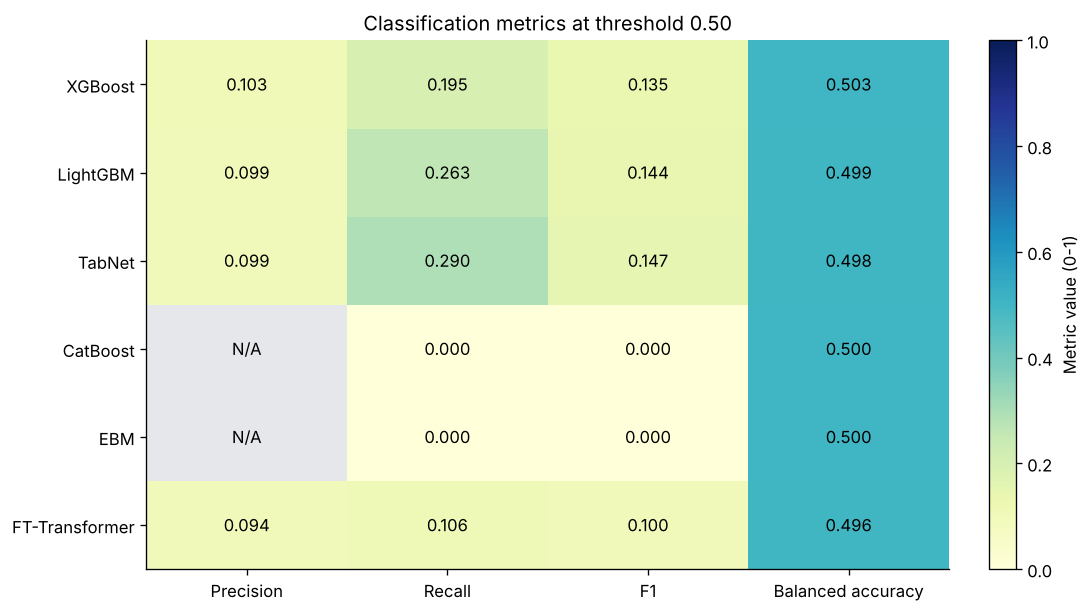

**Interpretation:** Higher recall may come from predicting many employees positive; compare precision and predicted-positive rates before interpreting detection quality.

In [11]:
threshold_metrics = ["precision", "recall", "f1", "balanced_accuracy"]
threshold_display = classification_display.set_index("model").loc[model_order, threshold_metrics]
display(classification_display[["model", "accuracy", "predicted_positive_rate"]])
display(comparison[["model", "f1_at_0_5", "f1_max_oof", "f1_max_threshold"]])
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
values = threshold_display.to_numpy(dtype=float)
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#e5e7eb")
im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for row in range(len(model_order)):
    for col in range(4):
        value = values[row, col]
        ax.text(col, row, "N/A" if np.isnan(value) else f"{value:.3f}", ha="center", va="center",
                color="white" if np.isfinite(value) and value > 0.55 else "black")
ax.set(xticks=range(4), xticklabels=["Precision", "Recall", "F1", "Balanced accuracy"],
       yticks=positions, yticklabels=model_order, title="Classification metrics at threshold 0.50")
fig.colorbar(im, ax=ax, label="Metric value (0-1)")
finish_figure(fig, "figure_07_fixed_threshold_metrics.png", "Higher recall may come from predicting many employees positive; compare precision and predicted-positive rates before interpreting detection quality.")


## 11. Classification errors

The six matrices share threshold 0.50 and a common 0-1 colour scale. Rows are true classes; columns are predicted classes. Annotations show counts and percentages **within each true class**, making minority-class errors visible despite imbalance.

Undefined row percentages would be N/A; canonical records contain both true classes. No employee-level records are displayed.


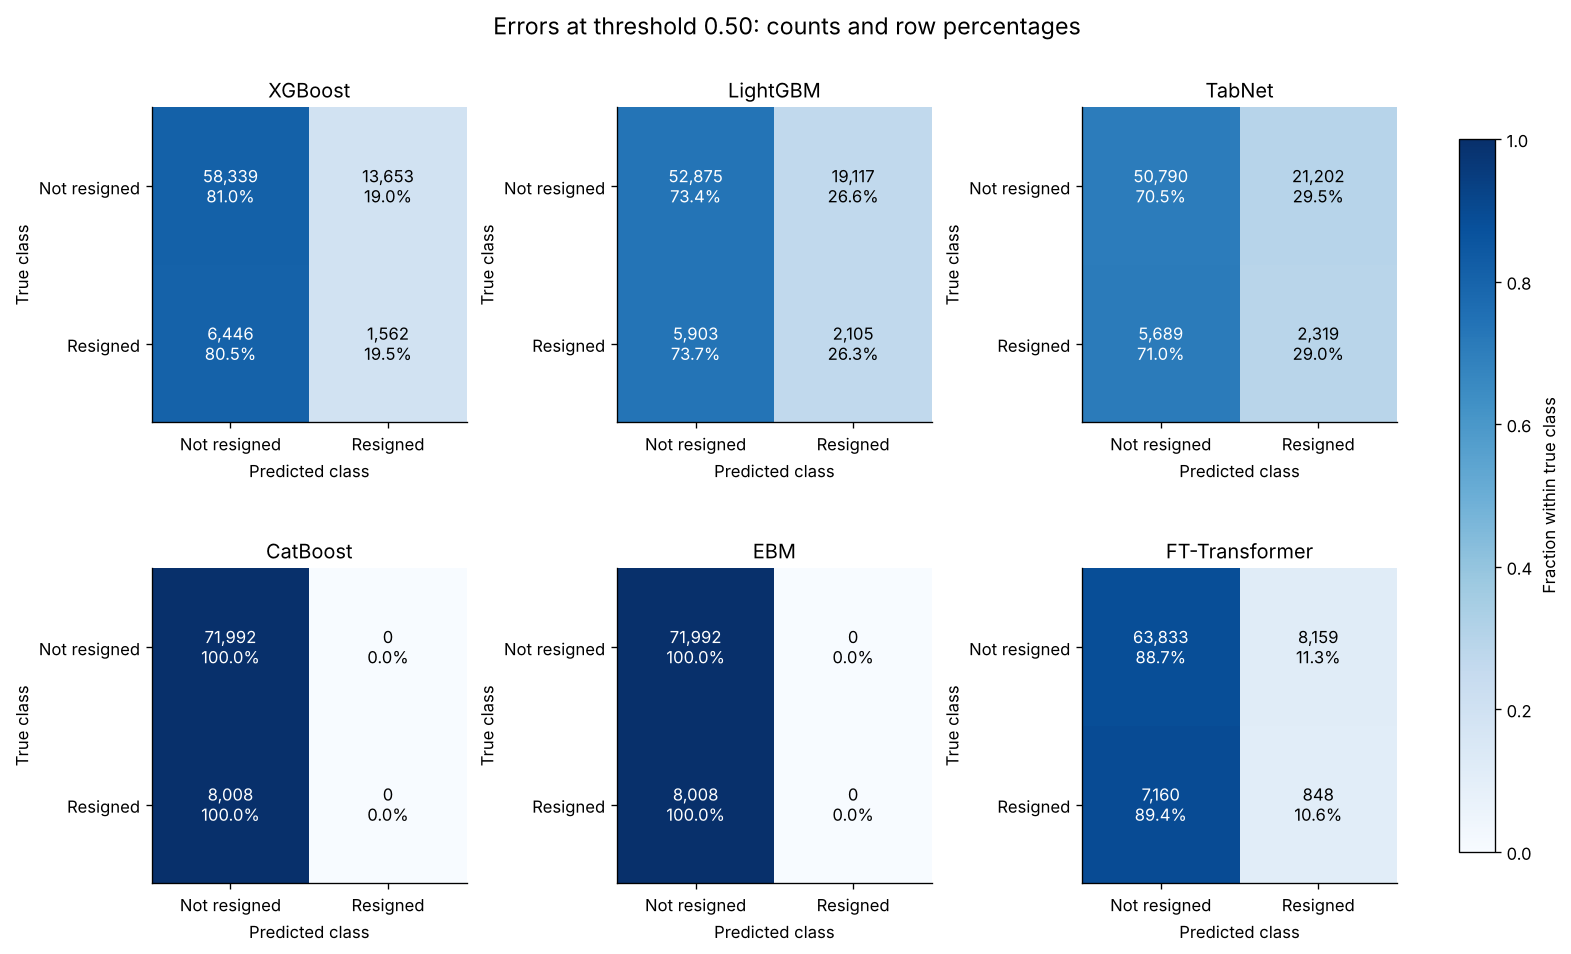

**Interpretation:** Compare missed resignations with false alarms; majority-class detection alone is insufficient.

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
normalized_matrices = {}
for ax, model in zip(axes.flat, model_order):
    counts = confusion_counts[model]
    denominators = counts.sum(axis=1, keepdims=True)
    normalized = np.divide(counts, denominators, out=np.full((2, 2), np.nan), where=denominators > 0)
    normalized_matrices[model] = normalized
    im = ax.imshow(np.ma.masked_invalid(normalized), cmap="Blues", vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            value = normalized[row, col]
            percentage = "N/A" if np.isnan(value) else f"{value:.1%}"
            ax.text(col, row, f"{counts[row, col]:,}\n{percentage}", ha="center", va="center",
                    color="white" if np.isfinite(value) and value > 0.5 else "black")
    ax.set(title=model, xticks=[0, 1], xticklabels=["Not resigned", "Resigned"],
           yticks=[0, 1], yticklabels=["Not resigned", "Resigned"], xlabel="Predicted class", ylabel="True class")
fig.colorbar(im, ax=list(axes.flat), label="Fraction within true class", shrink=0.8)
fig.suptitle("Errors at threshold 0.50: counts and row percentages", fontsize=14)
finish_figure(fig, "figure_08_confusion_matrix_comparison.png", "Compare missed resignations with false alarms; majority-class detection alone is insufficient.")


## 12. Protocol comparability and evidence boundaries

Registry declarations are separate from recorded metadata. Read details beside the canonical OOF inputs, not the newest run. Configured budgets are not assumed to be executed budgets. FT selection evidence is manifest-validated; other records are labelled saved metadata reports. Unavailable details remain **not recorded**.

CatBoost's full-development C03 metadata describes a different fit and is excluded from this per-fold inventory. Its canonical OOF predictions pass integrity checks and are suitable for descriptive OOF comparison. The repository does not preserve complete five-outer-fold candidate-selection and winner-refit provenance, so formal tuning evidence is incomplete; this does not prove its training was incorrect. EBM has three raw primary candidates and three standardized sensitivity variants. Shared folds support comparison of declared procedures, but budgets, representations, weighting and final fits can differ. No cross-hardware runtime ranking is attempted.


In [13]:
protocol_rows = []
for model in model_order:
    entry = registry["models"][model]
    directory = (ROOT / entry["oof_path"]).parent
    row = {"model": model, "registry_declared_protocol": entry["protocol"], "candidate_budget": "not recorded",
           "preprocessing": "not recorded", "weighting": "not recorded", "final_fit": "not recorded",
           "evidence_source": "canonical OOF; comparable per-fold metadata not recorded"}
    if model == "FT-Transformer":
        evidence_path = directory / "selection_evidence.json"
        measured = json.loads(evidence_path.read_text(encoding="utf-8"))
        assert len(measured) == 5 and all(len(item["all_candidates"]) == 8 for item in measured)
        row.update(candidate_budget="8 candidates x 5 folds; 5 winner refits",
                   preprocessing="Training-only numerical scaling / categorical vocabularies (formal adapter)",
                   weighting=", ".join(sorted({item["selected_weighting"] for item in measured})),
                   final_fit="All outer-training rows" if all(item["fitted_on_all_outer_rows"] for item in measured) else "See fold evidence",
                   evidence_source=str(evidence_path.relative_to(ROOT)) + " (manifest-validated)")
    elif model != "CatBoost":
        metadata_path = directory / "run_metadata.json"
        if metadata_path.exists():
            recorded = json.loads(metadata_path.read_text(encoding="utf-8"))
            row["evidence_source"] = str(metadata_path.relative_to(ROOT)) + " (saved metadata report)"
            if recorded.get("candidate_ids"):
                row["candidate_budget"] = f"{len(recorded['candidate_ids'])} candidates; {recorded.get('candidate_evaluations', 'not recorded')} inner evaluations"
            row["preprocessing"] = recorded.get("preprocessing", recorded.get("primary_preprocessing", "not recorded"))
            row["weighting"] = recorded.get("class_weighting", "not recorded")
            row["final_fit"] = recorded.get("refit_policy", "not recorded")
            if recorded.get("refit_on_all_outer_training_rows") is True:
                row["final_fit"] = "All outer-training rows (metadata report)"
            if model == "LightGBM":
                choices = {str(c['params'].get('class_weight')) for c in recorded.get('candidate_definitions', [])}
                row["weighting"] = "Candidate class_weight: " + ", ".join(sorted(choices)) if choices else "not recorded"
            if model == "EBM":
                primary = [c for c in recorded.get("candidate_settings", []) if c.get("preprocessing") == recorded.get("primary_preprocessing")]
                row["candidate_budget"] = f"{len(primary)} raw primary; {recorded.get('varieties', 'not recorded')} total variants including sensitivity"
    protocol_rows.append(row)
protocol_inventory = pd.DataFrame(protocol_rows)
display(protocol_inventory)
print("Registry declarations and supporting evidence are distinguished; missing details remain explicit.")


,model,registry_declared_protocol,candidate_budget,preprocessing,weighting,final_fit,evidence_source
0,XGBoost,Member 3 primary P1 one-hot; strict nested 8-candidate selection; P2/P3 preprocessing ...,8 candidates; 40 inner evaluations,fold-local OneHotEncoder(handle_unknown='ignore') on 4 categoricals; 13 numericals uns...,per-candidate; dynamic_ratio = n_neg/n_pos from the rows being fitted only,All outer-training rows (metadata report),results/models/xgboost/run_metadata.json (saved metadata report)
1,LightGBM,strict nested candidate selection,8 candidates; 40 inner evaluations,not recorded,"Candidate class_weight: None, balanced",full outer training at selected best iteration without early stopping,results/models/lightgbm/strict_nested/run_metadata.json (saved metadata report)
2,TabNet,strict nested candidate selection,8 candidates; 40 inner evaluations,not recorded,not recorded,not recorded,results/models/tabnet/run_metadata.json (saved metadata report)
3,CatBoost,"IT25100565 strict nested selection of 26 candidates per outer fold by inner log-loss, ...",not recorded,not recorded,not recorded,not recorded,canonical OOF; comparable per-fold metadata not recorded
4,EBM,nested inner-AP selection among three raw candidates; standardized variants are sensit...,3 raw primary; 6 total variants including sensitivity,raw,not recorded,not recorded,results/models/ebm/individual_IT25100429/run_metadata.json (saved metadata report)
5,FT-Transformer,strict nested FT01-FT08 inner AP candidate selection and full outer-training winner refit,8 candidates x 5 folds; 5 winner refits,Training-only numerical scaling / categorical vocabularies (formal adapter),"dynamic_ratio, none",All outer-training rows,results/models/ft_transformer/strict_nested/selection_evidence.json (manifest-validated)


Registry declarations and supporting evidence are distinguished; missing details remain explicit.


## 13. Group interpretation and selection decision

Report the numerical pooled-AP leader, baseline uplift and separate mean-fold leader. Calibration quality and discrimination answer different questions. Tiny score differences do not demonstrate significant or practical superiority.

No model, calibrator or threshold is frozen. Final holdout evaluation requires a separate valid freeze and authorization; holdout results must not be used to search for a better-looking winner.


In [14]:
leader = comparison.iloc[0]
mean_fold_leader = comparison.sort_values(["cv_ap_mean", "model"], ascending=[False, True]).iloc[0]
best_brier = comparison.sort_values(["brier_score", "model"], ascending=[True, True]).iloc[0]
summary = {
    "development_rows": int(len(reference_ids)),
    "positive_prevalence": prevalence,
    "ranking_leader": str(leader.model),
    "leader_pooled_average_precision": float(leader.pooled_average_precision),
    "leader_ap_uplift_over_prevalence": float(leader.ap_uplift_over_prevalence),
    "final_model_frozen": False,
    "reason_not_frozen": "All models remain near the no-skill baseline; candidate-selection and final-fit protocols differ across models.",
    "formal_holdout_accessed": False,
}
display(Markdown(
    f"**Pooled-AP leader: {leader.model}**, AP **{leader.pooled_average_precision:.6f}** "
    f"versus prevalence **{prevalence:.6f}**. The absolute uplift is "
    f"**{leader.ap_uplift_over_prevalence:.6f}** ({100 * leader.ap_uplift_over_prevalence:.3f} percentage points). "
    f"The mean-fold AP leader is **{mean_fold_leader.model}** "
    f"({mean_fold_leader.cv_ap_mean:.6f}); this illustrates why the aggregation rule matters.\n\n"
    f"**{best_brier.model}** has the lowest headline Brier score ({best_brier.brier_score:.6f}), "
    "which does not establish useful discrimination. All six results remain close to no-skill. "
    "Small differences and unequal training protocols do not establish a reliably superior model. "
    "**No final model is frozen; the formal holdout remains locked.**"
))
display(pd.DataFrame([summary]))


**Pooled-AP leader: XGBoost**, AP **0.101181** versus prevalence **0.100100**. The absolute uplift is **0.001081** (0.108 percentage points). The mean-fold AP leader is **TabNet** (0.101700); this illustrates why the aggregation rule matters.

**CatBoost** has the lowest headline Brier score (0.090102), which does not establish useful discrimination. All six results remain close to no-skill. Small differences and unequal training protocols do not establish a reliably superior model. **No final model is frozen; the formal holdout remains locked.**

,development_rows,positive_prevalence,ranking_leader,leader_pooled_average_precision,leader_ap_uplift_over_prevalence,final_model_frozen,reason_not_frozen,formal_holdout_accessed
0,80000,0.100100,XGBoost,0.101181,0.001081,False,All models remain near the no-skill baseline; candidate-selection and final-fit protoc...,False


In [15]:
# 14. Final checks and explicit aggregate export
expected_columns = ["model", "protocol", "tuning_complete", "pooled_average_precision", "pooled_roc_auc", "brier_score",
                    "ece_10_bins", "f1_at_0_5", "f1_max_oof", "f1_max_threshold", "cv_ap_mean", "cv_ap_sd",
                    "cv_roc_mean", "cv_roc_sd", "ap_uplift_over_prevalence"]
assert comparison.columns.tolist() == expected_columns
assert len(comparison) == 6 and set(comparison.model) == expected_models
assert len(folds) == 30 and folds.groupby("model").cv_fold.nunique().eq(5).all()
assert len(baselines) == 2 and baselines.columns.tolist() == ["model", "average_precision", "roc_auc", "brier_score", "accuracy", "recall", "f1"]
assert len(rendered_figures) == 8
assert not summary["final_model_frozen"] and not summary["formal_holdout_accessed"]
for model, predictions in frames.items():
    validate_oof_predictions(predictions, split_registry, source_data=source_targets,
                             expected_model_name=registry["models"][model].get("model_name", model))
    measured = calculate_binary_metrics(predictions.y_true, predictions.y_probability)
    for column, key in [("pooled_average_precision", "average_precision"), ("pooled_roc_auc", "roc_auc"), ("brier_score", "brier_score"), ("f1_at_0_5", "f1")]:
        assert np.isclose(indexed.loc[model, column], measured[key]), f"{model}: {column} mismatch"
    assert confusion_counts[model].sum() == len(reference_ids)
    assert np.allclose(normalized_matrices[model].sum(axis=1), 1)
    assert np.isclose(indexed.loc[model, "cv_ap_mean"], folds.loc[folds.model == model, "average_precision"].mean())
    assert np.isclose(indexed.loc[model, "cv_ap_sd"], folds.loc[folds.model == model, "average_precision"].std(ddof=1))
if EXPORT_RESULTS:
    out.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(out / "model_comparison.csv", index=False)
    folds.to_csv(out / "fold_metrics_long.csv", index=False)
    baselines.to_csv(out / "baseline_comparison.csv", index=False)
    (out / "comparison_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    for filename, figure in rendered_figures.items():
        figure.savefig(out / filename, dpi=160)
    for filename, expected in [("model_comparison.csv", comparison), ("fold_metrics_long.csv", folds), ("baseline_comparison.csv", baselines)]:
        pd.testing.assert_frame_equal(pd.read_csv(out / filename), expected, check_dtype=False, rtol=1e-12, atol=1e-12)
    assert json.loads((out / "comparison_summary.json").read_text(encoding="utf-8")) == summary
    assert all((out / filename).is_file() for filename in rendered_figures)
    display(pd.DataFrame({"exported_file": ["model_comparison.csv", "fold_metrics_long.csv", "baseline_comparison.csv", "comparison_summary.json", *rendered_figures]}))
else:
    print("Read-only completion: no directories created or result artifacts written.")
print("Verified: 6 canonical models, 2 Dummy references, 5 folds per model, 8 figure groups.")
print("No training, weight loading, model freeze or holdout evaluation.")


Read-only completion: no directories created or result artifacts written.
Verified: 6 canonical models, 2 Dummy references, 5 folds per model, 8 figure groups.
No training, weight loading, model freeze or holdout evaluation.


## 15. Conclusion and handoff

Canonical evidence ranks XGBoost first by pooled AP (approximately 0.101181) and TabNet first by mean fold AP (approximately 0.101700), against prevalence approximately 0.1001. The dynamic summary above is authoritative if canonical inputs are explicitly updated. These small numerical differences do not establish practical predictive value.

Representation, search budget, class weighting, stopping and refit protocols can differ. Missing recorded details remain explicit. Same-OOF maximum-F1 thresholds are exploratory, and weighted scores need separate probability-quality assessment.

Calibration, fairness and exploratory prioritization remain in their dedicated notebooks. Enable export only to deliberately refresh compatible aggregate outputs. **No model or threshold is frozen; the formal holdout remains locked.**


## 16. Cross-model development OOF agreement and error overlap

This section complements the team's six confusion matrices; it does not replace the headline ranking or recompute formal metrics. It aligns the six current canonical development OOF files again so these diagnostics can be checked independently. Binary comparisons use the fixed 0.50 cutoff. False-positive overlap is restricted to actual negatives, and false-negative overlap to actual positives. No threshold is optimized and no employee-level file is exported.

The team's eight figure groups remain unchanged. The three cross-model figures retain the distinct filenames already present on main. Aggregate CSV/PNG export follows the notebook's existing `EXPORT_RESULTS` switch.


In [16]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

cross_root = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "configs/analysis_registry.yaml").is_file()),
    None,
)
if cross_root is None:
    raise FileNotFoundError("Run this notebook from inside the project repository.")
if str(cross_root) not in sys.path:
    sys.path.insert(0, str(cross_root))
from src.evaluation.oof_validation import validate_oof_predictions

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
cross_out = cross_root / "results/comparison"
cross_registry = yaml.safe_load(
    (cross_root / "configs/analysis_registry.yaml").read_text(encoding="utf-8")
)
cross_models = ["FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"]
assert set(cross_registry["models"]) == set(cross_models)
cross_split = pd.read_csv(
    cross_root / "data/processed/split_registry.csv",
    usecols=["Employee_ID", "partition", "cv_fold"],
    dtype={"cv_fold": "Int64"},
)
assert len(cross_split) == 100_000 and cross_split.Employee_ID.is_unique
cross_development = cross_split.loc[cross_split.partition.eq("development")]
cross_holdout_ids = set(cross_split.loc[cross_split.partition.eq("holdout"), "Employee_ID"])
assert len(cross_development) == 80_000 and len(cross_holdout_ids) == 20_000
assert cross_development.cv_fold.value_counts().to_dict() == {
    fold: 16_000 for fold in range(1, 6)
}

cross_aligned = None
for model in cross_models:
    entry = cross_registry["models"][model]
    predictions = pd.read_csv(cross_root / entry["oof_path"])
    validate_oof_predictions(
        predictions, cross_split, expected_model_name=entry.get("model_name", model)
    )
    current = predictions[
        ["Employee_ID", "cv_fold", "y_true", "y_probability"]
    ].sort_values("Employee_ID").reset_index(drop=True)
    if cross_aligned is None:
        cross_aligned = current.rename(columns={"y_probability": model})
    else:
        for field in ("Employee_ID", "cv_fold", "y_true"):
            assert np.array_equal(
                cross_aligned[field].to_numpy(), current[field].to_numpy()
            ), f"{model}: {field} mismatch"
        cross_aligned[model] = current.y_probability.to_numpy()

assert len(cross_aligned) == 80_000 and cross_aligned.Employee_ID.is_unique
assert set(cross_aligned.Employee_ID) == set(cross_development.Employee_ID)
assert not set(cross_aligned.Employee_ID).intersection(cross_holdout_ids)
assert cross_aligned.cv_fold.value_counts().to_dict() == {
    fold: 16_000 for fold in range(1, 6)
}
cross_scores = cross_aligned[cross_models]
assert not cross_scores.isna().any().any()
assert np.isfinite(cross_scores.to_numpy(dtype=float)).all()
assert cross_scores.ge(0).all().all() and cross_scores.le(1).all().all()
cross_truth = cross_aligned.y_true.astype("int8")
assert set(cross_truth.unique()) == {0, 1}
print(
    f"Development OOF: {len(cross_aligned):,} unique IDs; "
    "five folds of 16,000; holdout overlap: 0."
)
print(
    f"Resigned: {int(cross_truth.sum()):,} "
    f"({cross_truth.mean():.2%}); no resampling."
)


Development OOF: 80,000 unique IDs; five folds of 16,000; holdout overlap: 0.
Resigned: 8,008 (10.01%); no resampling.


In [17]:
cross_binary = cross_scores.ge(0.50).astype("int8")
cross_votes = cross_binary.sum(axis=1).astype(int)
cross_confusion_rows = []
for model in cross_models:
    predicted = cross_binary[model]
    tn = int(((cross_truth == 0) & (predicted == 0)).sum())
    fp = int(((cross_truth == 0) & (predicted == 1)).sum())
    fn = int(((cross_truth == 1) & (predicted == 0)).sum())
    tp = int(((cross_truth == 1) & (predicted == 1)).sum())
    assert tn + fp + fn + tp == len(cross_aligned)
    cross_confusion_rows.append({
        "model": model, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "predicted_positive_count": fp + tp,
        "predicted_positive_rate": (fp + tp) / len(cross_aligned),
    })
cross_confusion_counts = pd.DataFrame(cross_confusion_rows)
cross_correct = cross_binary.eq(cross_truth, axis=0)
cross_shared_outcomes = pd.DataFrame([
    {"outcome": "correct_by_all_six", "employee_count": int(cross_correct.all(axis=1).sum())},
    {"outcome": "wrong_by_all_six", "employee_count": int((~cross_correct).all(axis=1).sum())},
    {"outcome": "all_six_predict_negative", "employee_count": int(cross_votes.eq(0).sum())},
    {"outcome": "all_six_predict_positive", "employee_count": int(cross_votes.eq(6).sum())},
    {"outcome": "at_least_one_model_disagreement", "employee_count": int(cross_votes.between(1, 5).sum())},
    {"outcome": "maximum_disagreement_three_vs_three", "employee_count": int(cross_votes.eq(3).sum())},
])
cross_shared_outcomes["percentage_of_development"] = (
    100 * cross_shared_outcomes.employee_count / len(cross_aligned)
)
cross_overlap_rows = []
for error_type, votes, denominator in (
    ("false_positive", cross_votes.loc[cross_truth.eq(0)], int(cross_truth.eq(0).sum())),
    ("false_negative", 6 - cross_votes.loc[cross_truth.eq(1)], int(cross_truth.eq(1).sum())),
):
    for minimum_models in range(1, 7):
        count = int(votes.ge(minimum_models).sum())
        cross_overlap_rows.append({
            "error_type": error_type, "minimum_models": minimum_models,
            "employee_count": count, "class_denominator": denominator,
            "percentage_of_class": 100 * count / denominator,
        })
cross_error_overlap = pd.DataFrame(cross_overlap_rows)
assert cross_error_overlap.groupby("error_type").employee_count.apply(
    lambda counts: counts.is_monotonic_decreasing
).all()
cross_vote_distribution = (
    cross_votes.value_counts().reindex(range(7), fill_value=0)
    .rename_axis("positive_vote_count").reset_index(name="employee_count")
)
cross_vote_distribution["percentage"] = (
    100 * cross_vote_distribution.employee_count / len(cross_aligned)
)
assert cross_vote_distribution.employee_count.sum() == 80_000
assert (cross_confusion_counts.tn + cross_confusion_counts.fp).eq(71_992).all()
assert (cross_confusion_counts.fn + cross_confusion_counts.tp).eq(8_008).all()
display(cross_shared_outcomes, cross_error_overlap, cross_vote_distribution)


,outcome,employee_count,percentage_of_development
0,correct_by_all_six,25787,32.233750
1,wrong_by_all_six,2947,3.683750
2,all_six_predict_negative,28734,35.917500
3,all_six_predict_positive,0,0.000000
4,at_least_one_model_disagreement,51266,64.082500
5,maximum_disagreement_three_vs_three,1864,2.330000


,error_type,minimum_models,employee_count,class_denominator,percentage_of_class
0,false_positive,1,46205,71992,64.180742
1,false_positive,2,14256,71992,19.802200
2,false_positive,3,1670,71992,2.319702
3,false_positive,4,0,71992,0.000000
4,false_positive,5,0,71992,0.000000
5,false_positive,6,0,71992,0.000000
6,false_negative,1,8008,8008,100.000000
7,false_negative,2,8008,8008,100.000000
8,false_negative,3,8008,8008,100.000000
9,false_negative,4,7814,8008,97.577423


,positive_vote_count,employee_count,percentage
0,0,28734,35.917500
1,1,35431,44.288750
2,2,13971,17.463750
3,3,1864,2.330000
4,4,0,0.000000
5,5,0,0.000000
6,6,0,0.000000


In [18]:
cross_agreement = pd.DataFrame(index=cross_models, columns=cross_models, dtype=float)
for left in cross_models:
    for right in cross_models:
        cross_agreement.loc[left, right] = float(
            cross_binary[left].eq(cross_binary[right]).mean()
        )
cross_correlation = cross_scores.corr(method="pearson")
cross_top_risk = {}
for percent in (1, 5, 10):
    count = len(cross_aligned) * percent // 100
    top_ids = {
        model: set(
            cross_aligned.sort_values(
                [model, "Employee_ID"], ascending=[False, True], kind="mergesort"
            ).head(count).Employee_ID
        )
        for model in cross_models
    }
    assert all(len(ids) == count for ids in top_ids.values())
    matrix = pd.DataFrame(index=cross_models, columns=cross_models, dtype=float)
    for left in cross_models:
        for right in cross_models:
            intersection = len(top_ids[left] & top_ids[right])
            matrix.loc[left, right] = intersection / (2 * count - intersection)
    cross_top_risk[percent] = matrix

for matrix in (cross_agreement, cross_correlation, *cross_top_risk.values()):
    values = matrix.to_numpy(dtype=float)
    assert matrix.shape == (6, 6) and np.isfinite(values).all()
    assert np.allclose(values, values.T) and np.allclose(np.diag(values), 1)
assert cross_agreement.to_numpy().min() >= 0
assert all(matrix.to_numpy().min() >= 0 for matrix in cross_top_risk.values())
assert np.abs(cross_correlation.to_numpy()).max() <= 1 + 1e-12

cross_ft_xgb_pooled = cross_correlation.loc["FT-Transformer", "XGBoost"]
cross_ft_xgb_within_fold = pd.Series({
    int(fold): cross_scores.loc[
        cross_aligned.cv_fold.eq(fold), "FT-Transformer"
    ].corr(cross_scores.loc[
        cross_aligned.cv_fold.eq(fold), "XGBoost"
    ])
    for fold in range(1, 6)
}, name="within_fold_pearson")
cross_centered_scores = cross_scores - cross_scores.groupby(
    cross_aligned.cv_fold
).transform("mean")
cross_ft_xgb_centered = cross_centered_scores[
    "FT-Transformer"
].corr(cross_centered_scores["XGBoost"])
display(cross_agreement, cross_correlation, cross_top_risk[5])
print(
    f"FT–XGBoost Pearson: pooled {cross_ft_xgb_pooled:.6f}; "
    f"fold-mean-adjusted pooled {cross_ft_xgb_centered:.6f}."
)
display(cross_ft_xgb_within_fold.to_frame())


,FT-Transformer,CatBoost,XGBoost,LightGBM,EBM,TabNet
FT-Transformer,1.000000,0.887413,0.697225,0.696087,0.887413,0.610350
CatBoost,0.887413,1.000000,0.809813,0.734725,1.000000,0.705987
XGBoost,0.697225,0.809813,1.000000,0.727612,0.809813,0.639700
LightGBM,0.696087,0.734725,0.727612,1.000000,0.734725,0.531913
EBM,0.887413,1.000000,0.809813,0.734725,1.000000,0.705987
TabNet,0.610350,0.705987,0.639700,0.531913,0.705987,1.000000


,FT-Transformer,CatBoost,XGBoost,LightGBM,EBM,TabNet
FT-Transformer,1.000000,0.013358,-0.974633,-0.212934,0.001779,-0.189983
CatBoost,0.013358,1.000000,0.052760,0.042208,0.369000,0.020288
XGBoost,-0.974633,0.052760,1.000000,0.231312,0.077509,0.168439
LightGBM,-0.212934,0.042208,0.231312,1.000000,0.020923,-0.597264
EBM,0.001779,0.369000,0.077509,0.020923,1.000000,0.017127
TabNet,-0.189983,0.020288,0.168439,-0.597264,0.017127,1.000000


,FT-Transformer,CatBoost,XGBoost,LightGBM,EBM,TabNet
FT-Transformer,1.000000,0.076281,0.000000,0.160598,0.000000,0.000000
CatBoost,0.076281,1.000000,0.047395,0.086071,0.098147,0.033993
XGBoost,0.000000,0.047395,1.000000,0.031460,0.095890,0.042481
LightGBM,0.160598,0.086071,0.031460,1.000000,0.022495,0.006163
EBM,0.000000,0.098147,0.095890,0.022495,1.000000,0.030662
TabNet,0.000000,0.033993,0.042481,0.006163,0.030662,1.000000


FT–XGBoost Pearson: pooled -0.974633; fold-mean-adjusted pooled 0.065190.


,within_fold_pearson
1,0.304222
2,0.012001
3,0.205365
4,0.214137
5,0.026288


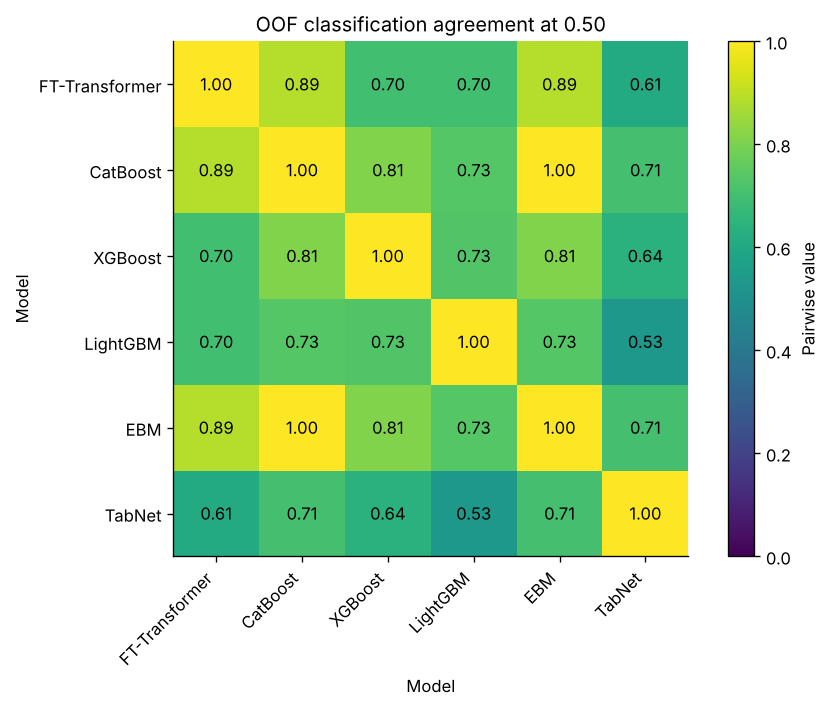

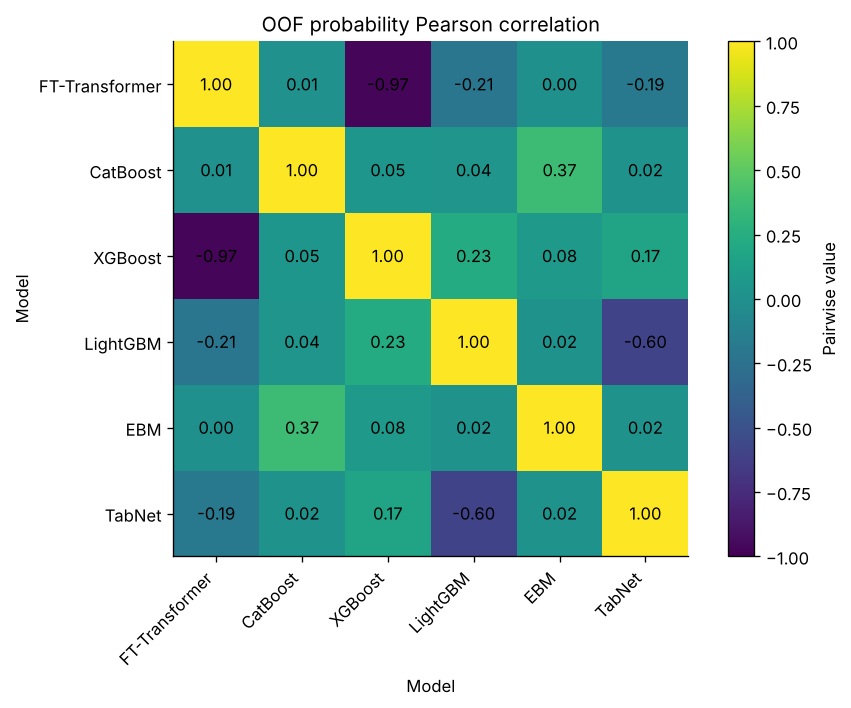

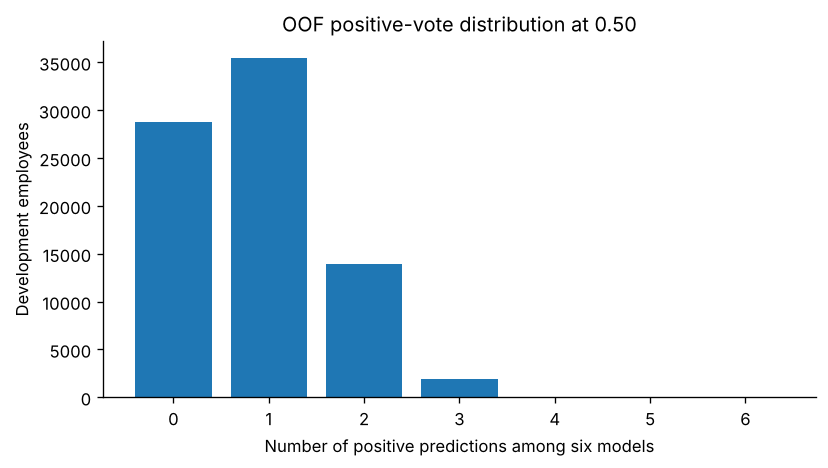

Read-only cross-model display; no comparison artifacts written.
No model training or holdout predictions were used.


In [19]:
cross_tables = {
    "confusion_counts.csv": cross_confusion_counts,
    "shared_outcomes.csv": cross_shared_outcomes,
    "error_overlap_summary.csv": cross_error_overlap,
    "classification_agreement.csv": cross_agreement,
    "probability_correlation.csv": cross_correlation,
    "prediction_vote_distribution.csv": cross_vote_distribution,
    **{
        f"top_risk_overlap_{percent}pct.csv": matrix
        for percent, matrix in cross_top_risk.items()
    },
}
cross_export = bool(globals().get("EXPORT_RESULTS", False))
if cross_export:
    cross_out.mkdir(parents=True, exist_ok=True)
    for filename, table in cross_tables.items():
        is_matrix = filename.endswith("agreement.csv") or filename.startswith(
            ("probability_correlation", "top_risk_overlap")
        )
        table.to_csv(
            cross_out / filename,
            index=is_matrix,
            index_label="model" if is_matrix else None,
        )

def cross_show_matrix(matrix, title, filename, lower, upper):
    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(matrix.to_numpy(), vmin=lower, vmax=upper)
    ax.set_xticks(range(6), labels=cross_models, rotation=45, ha="right")
    ax.set_yticks(range(6), labels=cross_models)
    ax.set_xlabel("Model")
    ax.set_ylabel("Model")
    ax.set_title(title)
    for row in range(6):
        for column in range(6):
            ax.text(
                column, row, f"{matrix.iloc[row, column]:.2f}",
                ha="center", va="center"
            )
    fig.colorbar(image, ax=ax, label="Pairwise value")
    fig.tight_layout()
    if cross_export:
        fig.savefig(cross_out / filename, dpi=160)
    display(fig)
    plt.close(fig)

cross_show_matrix(
    cross_agreement, "OOF classification agreement at 0.50",
    "figure_04_classification_agreement.png", 0, 1
)
cross_show_matrix(
    cross_correlation, "OOF probability Pearson correlation",
    "figure_05_probability_correlation.png", -1, 1
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    cross_vote_distribution.positive_vote_count,
    cross_vote_distribution.employee_count
)
ax.set_xticks(range(7))
ax.set_xlabel("Number of positive predictions among six models")
ax.set_ylabel("Development employees")
ax.set_title("OOF positive-vote distribution at 0.50")
fig.tight_layout()
if cross_export:
    fig.savefig(cross_out / "figure_06_prediction_vote_distribution.png", dpi=160)
display(fig)
plt.close(fig)
if cross_export:
    assert all((cross_out / filename).is_file() for filename in cross_tables)
    print("Exported nine cross-model tables and three cross-model figures.")
else:
    print("Read-only cross-model display; no comparison artifacts written.")
print("No model training or holdout predictions were used.")


### Cross-model interpretation and limits

On the current canonical development OOF inputs, all six models are correct for 20,469 employees and wrong for 2,368; at least one binary prediction differs for 57,163. EBM predicts no positives at 0.50, so all-six-positive counts are zero. Among 8,008 actual resignations, 2,368 (29.57%) are false negatives for all six. These threshold-dependent descriptions do not show that agreement implies correctness; frequent shared negative predictions may partly reflect the approximately 10% positive prevalence. The false-positive and false-negative overlap tables use actual-class denominators.

Pearson probability correlation describes linear similarity in scores, not causation or identical ranking. The pooled FT-Transformer–XGBoost value is approximately **−0.974633**, mainly because their fold-level probability baselines differ. All five within-fold correlations are nonnegative, and the pooled correlation after subtracting each model's fold mean is approximately **+0.065**. The pooled negative value does **not** show that the models rank individual employees in exactly opposite ways.

Top-risk Jaccard overlap describes agreement among the highest-scored development employees at 1%, 5% and 10%, with Employee_ID breaking ties. It does not define an intervention threshold or select a final model. No formal-holdout predictions or outcomes are used.
